In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the dataset

df = pd.read_csv("Housing.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display the first 5 rows

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
# Check the number of rows and columns

print("Dataset Shape:", df.shape)

Dataset Shape: (545, 13)


In [5]:
# Check dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
# Check for missing values

df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [7]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [8]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Categorical Columns:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [9]:
# Basic statistical summary of numerical columns

df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


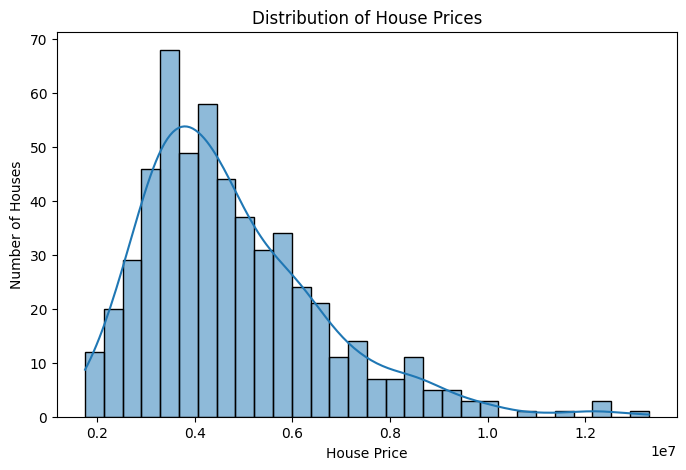

In [10]:
# Visualize the distribution of house prices

plt.figure(figsize=(8, 5))

sns.histplot(df['price'], bins=30, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Number of Houses')

plt.show()

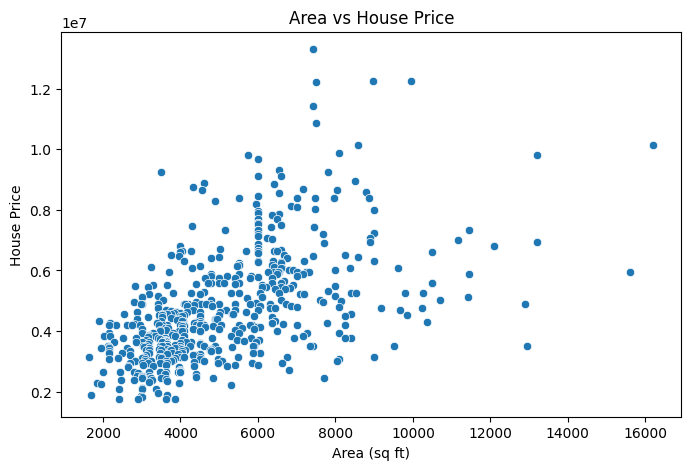

In [11]:
# Relationship between area and house price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='area', y='price')

plt.title('Area vs House Price')
plt.xlabel('Area (sq ft)')
plt.ylabel('House Price')

plt.show()

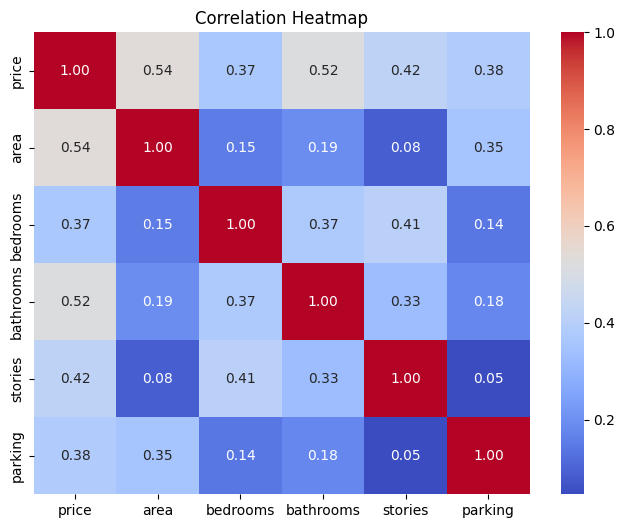

In [12]:
# Check correlation between numerical variables

plt.figure(figsize=(8, 6))

correlation_matrix = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

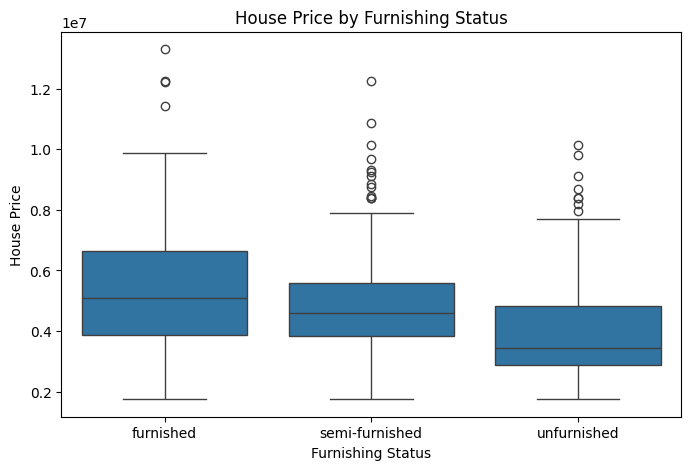

In [13]:
# Compare house prices across furnishing status

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='furnishingstatus', y='price')

plt.title('House Price by Furnishing Status')
plt.xlabel('Furnishing Status')
plt.ylabel('House Price')

plt.show()

In [14]:
# Check unique values in categorical columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


mainroad:
['yes' 'no']

guestroom:
['no' 'yes']

basement:
['no' 'yes']

hotwaterheating:
['no' 'yes']

airconditioning:
['yes' 'no']

prefarea:
['yes' 'no']

furnishingstatus:
['furnished' 'semi-furnished' 'unfurnished']


In [15]:
# Separate features (X) and target (y)

X = df.drop('price', axis=1)
y = df['price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (545, 12)
y shape: (545,)


In [16]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training data shape: (436, 12)
Testing data shape: (109, 12)
Training target shape: (436,)
Testing target shape: (109,)


In [17]:
# Define numerical and categorical features

numerical_features = [
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

categorical_features = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea',
    'furnishingstatus'
]


# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
# Create a complete pipeline:
# Preprocessing + Linear Regression

linear_regression_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

print("Linear Regression pipeline created successfully!")

Linear Regression pipeline created successfully!


In [19]:
# Train the Linear Regression model

linear_regression_pipeline.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [20]:
# Make predictions on the test data

y_pred_lr = linear_regression_pipeline.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_lr))

Predictions generated successfully!
Number of predictions: 109


In [21]:
# Compare actual prices with predicted prices

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_lr
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5.164654e+06
1,6650000,7.224722e+06
2,3710000,3.109863e+06
3,6440000,4.612075e+06
4,2800000,3.294646e+06
5,4900000,3.532275e+06
6,5250000,5.611775e+06
7,4543000,6.368146e+06
8,2450000,2.722857e+06
9,3353000,2.629406e+06


In [22]:
# Calculate regression metrics for Linear Regression

mae_lr = mean_absolute_error(y_test, y_pred_lr)

mse_lr = mean_squared_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mse_lr)

r2_lr = r2_score(y_test, y_pred_lr)


print("Linear Regression Results")
print("-------------------------")
print("MAE  :", mae_lr)
print("MSE  :", mse_lr)
print("RMSE :", rmse_lr)
print("R²   :", r2_lr)

Linear Regression Results
-------------------------
MAE  : 970043.403920164
MSE  : 1754318687330.6667
RMSE : 1324506.9600914398
R²   : 0.6529242642153178


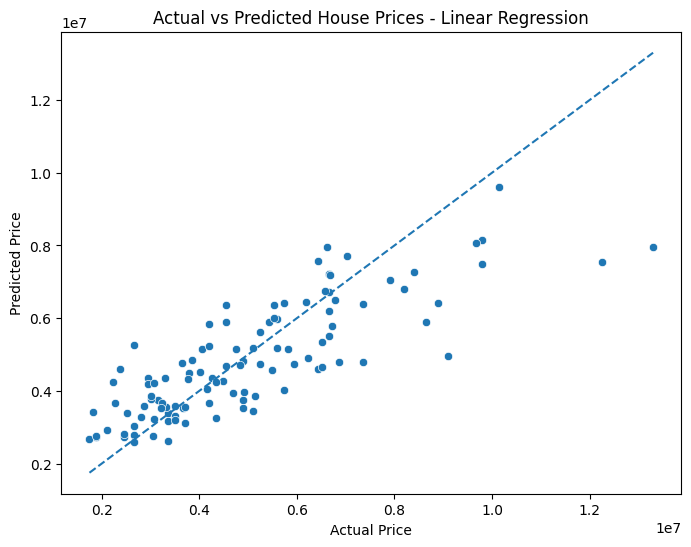

In [23]:
# Actual vs Predicted Prices

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred_lr)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted House Prices - Linear Regression')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')

plt.show()

In [24]:
# Create preprocessing pipeline for Random Forest
# Random Forest does not need StandardScaler

rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# Create Random Forest pipeline

random_forest_pipeline = Pipeline(
    steps=[
        ('preprocessor', rf_preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [25]:
# Train the Random Forest model

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [26]:
# Make predictions using Random Forest

y_pred_rf = random_forest_pipeline.predict(X_test)

print("Random Forest predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))

Random Forest predictions generated successfully!
Number of predictions: 109


In [27]:
# Calculate regression metrics for Random Forest

mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)


print("Random Forest Results")
print("---------------------")
print("MAE  :", mae_rf)
print("MSE  :", mse_rf)
print("RMSE :", rmse_rf)
print("R²   :", r2_rf)

Random Forest Results
---------------------
MAE  : 1013968.579587156
MSE  : 1954727417859.5308
RMSE : 1398115.6668385956
R²   : 0.6132752494107068


In [28]:
# Compare Linear Regression and Random Forest

model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae_lr, mae_rf],
    'MSE': [mse_lr, mse_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R²': [r2_lr, r2_rf]
})

model_comparison

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,9.700434e+05,1.754319e+12,1.324507e+06,0.652924
1,Random Forest,1.013969e+06,1.954727e+12,1.398116e+06,0.613275


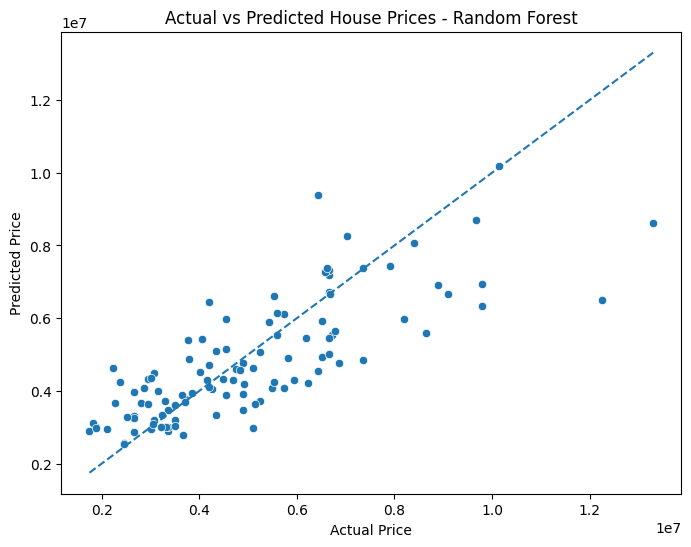

In [29]:
# Actual vs Predicted Prices - Random Forest

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred_rf)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted House Prices - Random Forest')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')

plt.show()

In [30]:
import joblib

# Save the complete Linear Regression pipeline

joblib.dump(
    linear_regression_pipeline,
    'house_price_linear_regression_model.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [31]:
# Load the saved model

loaded_model = joblib.load('house_price_linear_regression_model.pkl')

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Check whether predictions match the original model
print("Saved model loaded successfully!")

print(
    "Predictions match:",
    np.allclose(y_pred_lr, loaded_predictions)
)

Saved model loaded successfully!
Predictions match: True
